In [36]:
import cv2
import numpy as np
import heapq
import matplotlib.pyplot as plt
from skimage.feature import graycomatrix, graycoprops
from sklearn.cluster import KMeans
from skimage.metrics import structural_similarity as ssim


## Problem 1: Comparative Edge Detection on Natural Images

## Download any outdoor natural image containing trees, buildings, or roads. Apply Sobel, Laplacian, and Canny edge detection to the image. Compare the outputs and identify which operator captures the most meaningful edges and why.


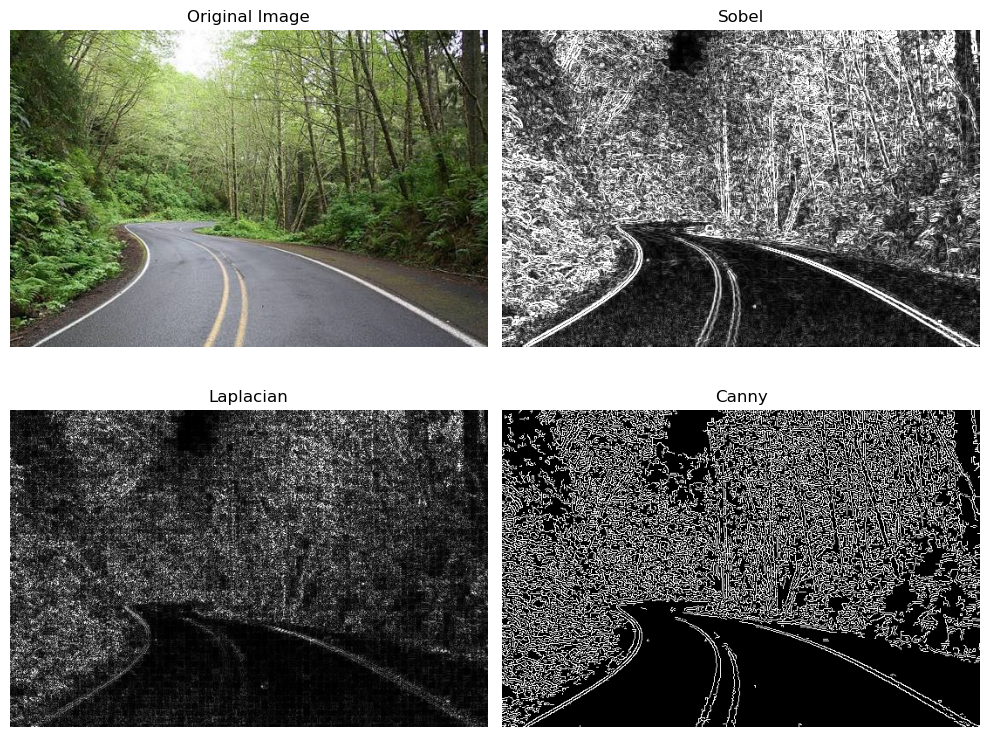

In [5]:
# Read the outdoor image in colour
img = cv2.imread(r"C:\Users\hpw\Downloads\IPP_ASSIGNMENT_3\outdoor.jpeg")

gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY) # Convert the image to grayscale
sobel_x = cv2.Sobel(gray, cv2.CV_64F, 1, 0, ksize=3) # Apply Sobel edge detection in X direction
sobel_y = cv2.Sobel(gray, cv2.CV_64F, 0, 1, ksize=3) # Apply Sobel edge detection in Y direction
sobel = cv2.magnitude(sobel_x, sobel_y) # Combine Sobel X and Y results
sobel = cv2.convertScaleAbs(sobel) # Convert Sobel result for display
laplacian = cv2.Laplacian(gray, cv2.CV_64F) # Apply Laplacian edge detection
laplacian = cv2.convertScaleAbs(laplacian) # Convert Laplacian result for display
canny = cv2.Canny(gray, 100, 200) # Apply Canny edge detection

# Display the original image
plt.figure(figsize=(10, 8))
plt.subplot(2, 2, 1)
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title("Original Image")
plt.axis("off")

# Display Sobel edges
plt.subplot(2, 2, 2)
plt.imshow(sobel, cmap="gray")
plt.title("Sobel")
plt.axis("off")

# Display Laplacian edges
plt.subplot(2, 2, 3)
plt.imshow(laplacian, cmap="gray")
plt.title("Laplacian")
plt.axis("off")

# Display Canny edges
plt.subplot(2, 2, 4)
plt.imshow(canny, cmap="gray")
plt.title("Canny")
plt.axis("off")

# Adjust the layout
plt.tight_layout()

# Show all results
plt.show()


## Problem 2: Noise Sensitivity Experiment

## Take a clean grayscale image and add Gaussian noise and salt-and-pepper noise. Apply Sobel and Laplacian edge detection to both noisy images. Compare the results and observe which operator is more affected by noise, how edge clarity changes, and which preprocessing step improves the results.

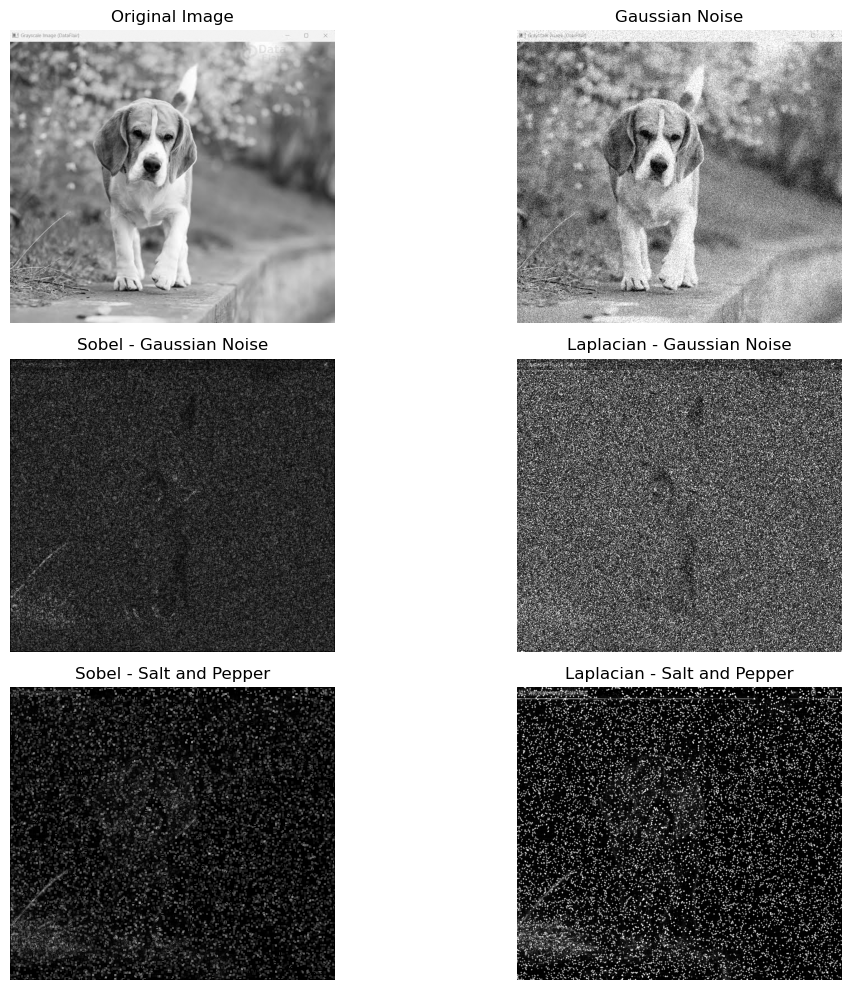

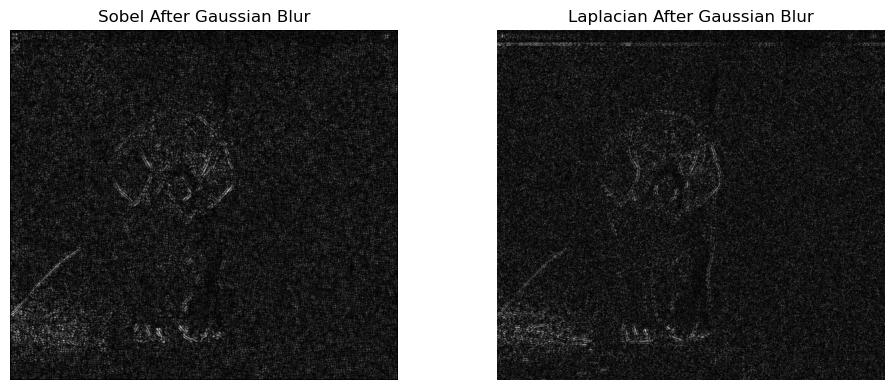

In [51]:
# Load the grayscale image
img = cv2.imread(r"C:\Users\hpw\Downloads\IPP_ASSIGNMENT_3\clean.jpeg",cv2.IMREAD_GRAYSCALE)

# Check whether the image was loaded
if img is None:
    print("Image not found. Please check the file path and filename.")

else:
    # Add Gaussian noise
    gaussian_noise = np.random.normal(0, 25, img.shape)
    gaussian = np.clip(img + gaussian_noise, 0, 255).astype(np.uint8)

    # Add salt-and-pepper noise
    salt_pepper = img.copy()
    random_values = np.random.random(img.shape)

    salt_pepper[random_values < 0.02] = 0
    salt_pepper[random_values > 0.98] = 255

    # Apply Sobel and Laplacian to Gaussian noisy image
    sobel_gaussian = cv2.Sobel(gaussian, cv2.CV_64F, 1, 1, ksize=3)
    laplacian_gaussian = cv2.Laplacian(gaussian, cv2.CV_64F)

    # Apply Sobel and Laplacian to salt-and-pepper noisy image
    sobel_sp = cv2.Sobel(salt_pepper, cv2.CV_64F, 1, 1, ksize=3)
    laplacian_sp = cv2.Laplacian(salt_pepper, cv2.CV_64F)

    # Convert results for display
    sobel_gaussian = cv2.convertScaleAbs(sobel_gaussian)
    laplacian_gaussian = cv2.convertScaleAbs(laplacian_gaussian)
    sobel_sp = cv2.convertScaleAbs(sobel_sp)
    laplacian_sp = cv2.convertScaleAbs(laplacian_sp)

    # Display results
    plt.figure(figsize=(12, 10))

    plt.subplot(3, 2, 1)
    plt.imshow(img, cmap="gray")
    plt.title("Original Image")
    plt.axis("off")

    plt.subplot(3, 2, 2)
    plt.imshow(gaussian, cmap="gray")
    plt.title("Gaussian Noise")
    plt.axis("off")

    plt.subplot(3, 2, 3)
    plt.imshow(sobel_gaussian, cmap="gray")
    plt.title("Sobel - Gaussian Noise")
    plt.axis("off")

    plt.subplot(3, 2, 4)
    plt.imshow(laplacian_gaussian, cmap="gray")
    plt.title("Laplacian - Gaussian Noise")
    plt.axis("off")

    plt.subplot(3, 2, 5)
    plt.imshow(sobel_sp, cmap="gray")
    plt.title("Sobel - Salt and Pepper")
    plt.axis("off")

    plt.subplot(3, 2, 6)
    plt.imshow(laplacian_sp, cmap="gray")
    plt.title("Laplacian - Salt and Pepper")
    plt.axis("off")

    plt.tight_layout()
    plt.show()

# Apply Gaussian blur to reduce noise
blurred = cv2.GaussianBlur(gaussian, (5, 5), 0)

# Apply Sobel after reducing noise
sobel_blur = cv2.Sobel(blurred, cv2.CV_64F, 1, 1, ksize=3)

# Apply Laplacian after reducing noise
laplacian_blur = cv2.Laplacian(blurred, cv2.CV_64F)

# Display the results
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(cv2.convertScaleAbs(sobel_blur), cmap="gray")
plt.title("Sobel After Gaussian Blur")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(cv2.convertScaleAbs(laplacian_blur), cmap="gray")
plt.title("Laplacian After Gaussian Blur")
plt.axis("off")

plt.tight_layout()
plt.show()


### Observation

Gaussian noise and salt-and-pepper noise create unwanted responses in both edge detection methods. Laplacian is generally more sensitive to noise because it responds strongly to rapid intensity changes. Sobel is also affected, but may preserve the main edges more clearly.

### Conclusion

Gaussian blur helps reduce noise before applying edge detection. It improves edge clarity, although excessive blurring can remove some fine details.



## Problem 3: Compression Ratio Comparison (RLE vs Huffman)

## Load a grayscale image with large smooth regions, such as a document scan or sky image. Compress the image using Run-Length Encoding (RLE) and Huffman Coding separately. Calculate and compare the bit-length before compression, bit-length after compression, and percentage reduction. Explain why each technique performed the way it did.


Original Size: 1598520 bits
RLE Compressed Size (estimated): 5878000 bits
RLE Reduction: -267.72 %
Huffman Compressed Size: 1479046 bits
Huffman Reduction: 7.47 %


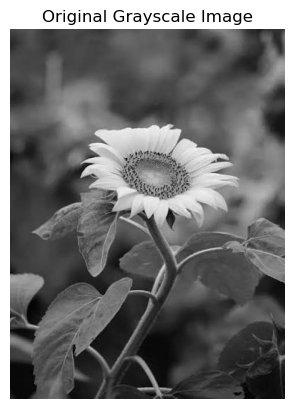

In [53]:
# Load the grayscale image
img = cv2.imread(
    r"C:\Users\hpw\Downloads\IPP_ASSIGNMENT_3\smooth.png",cv2.IMREAD_GRAYSCALE)

if img is None:
    print("Image not found")

else:
    # Convert image into a list of pixels
    pixels = img.flatten()

    # Calculate original size
    original_bits = len(pixels) * 8

    # RLE Compression
    rle = []
    count = 1

    for i in range(1, len(pixels)):
        if pixels[i] == pixels[i - 1]:
            count = count + 1
        else:
            rle.append((pixels[i - 1], count))
            count = 1

    rle.append((pixels[-1], count))

    # Calculate RLE compressed size
    rle_bits = len(rle) * 40

    # Huffman Coding
    freq = {}

    for pixel in pixels:
        freq[pixel] = freq.get(pixel, 0) + 1

    # Create Huffman tree
    heap = [[weight, [[pixel, ""]]]
            for pixel, weight in freq.items()]

    heapq.heapify(heap)

    if len(heap) == 1:
        codes = {heap[0][1][0][0]: "0"}

    else:
        while len(heap) > 1:
            left = heapq.heappop(heap)
            right = heapq.heappop(heap)

            for item in left[1]:
                item[1] = "0" + item[1]

            for item in right[1]:
                item[1] = "1" + item[1]

            heapq.heappush(
                heap,
                [left[0] + right[0], left[1] + right[1]]
            )

        codes = dict(heap[0][1])

    # Calculate Huffman compressed size
    huffman_bits = 0

    for pixel in freq:
        huffman_bits += freq[pixel] * len(codes[pixel])

    # Calculate percentage reduction
    rle_reduction = ((original_bits - rle_bits) / original_bits) * 100
    huffman_reduction = ((original_bits - huffman_bits) / original_bits) * 100

    # Print the results
    print("Original Size:", original_bits, "bits")

    print("RLE Compressed Size (estimated):", rle_bits, "bits")
    print("RLE Reduction:", round(rle_reduction, 2), "%")

    print("Huffman Compressed Size:", huffman_bits, "bits")
    print("Huffman Reduction:", round(huffman_reduction, 2), "%")

    # Display the original image
    plt.imshow(img, cmap="gray")
    plt.title("Original Grayscale Image")
    plt.axis("off")
    plt.show()


### Observation

RLE increased the estimated image size because the flower image contains few long runs of identical pixel values. Huffman coding reduced the encoded pixel size by assigning shorter codes to frequently occurring pixel values.

### Conclusion

RLE is more suitable for images with large uniform regions, while Huffman coding can be more effective when pixel frequencies are uneven. The performance of both methods depends on the image.


## Problem 4: JPEG Block Artifact Analysis

## Implement 8×8 block-based JPEG-style compression using DCT and quantisation. Compress the same image using low, medium, and high quantisation levels. Analyze the block artifacts, texture loss, PSNR, and SSIM.

Low Quantisation
PSNR: 44.77
SSIM: 0.9967

Medium Quantisation
PSNR: 26.0
SSIM: 0.8389

High Quantisation
PSNR: 23.6
SSIM: 0.7451



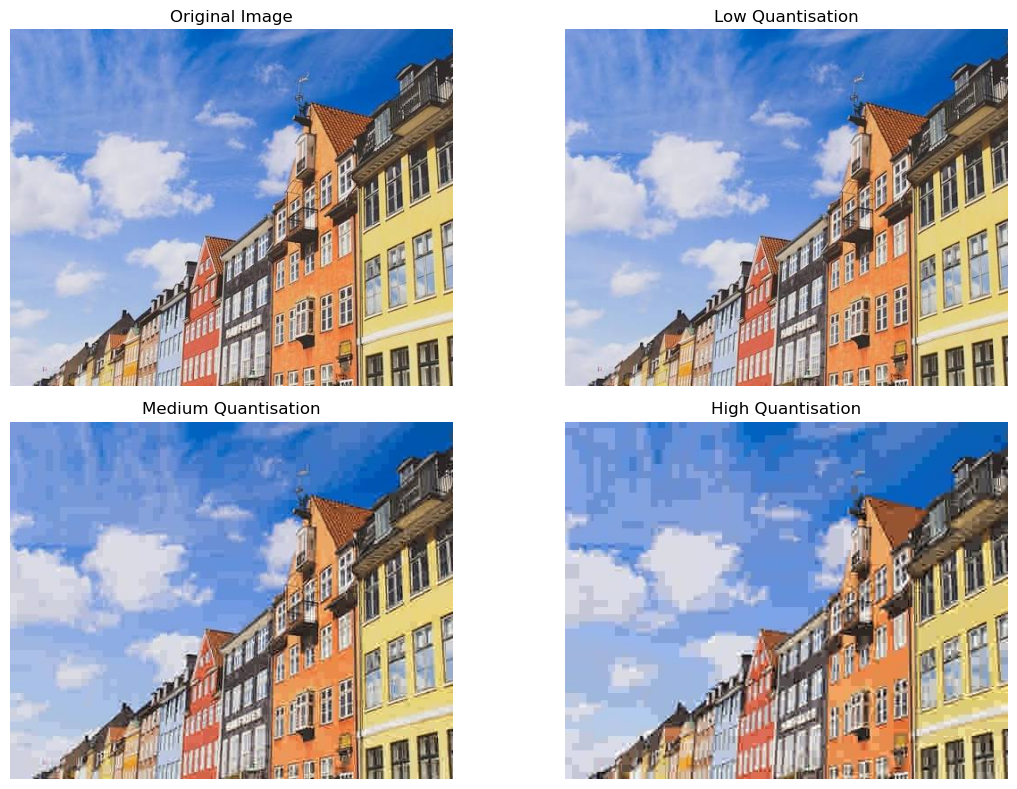

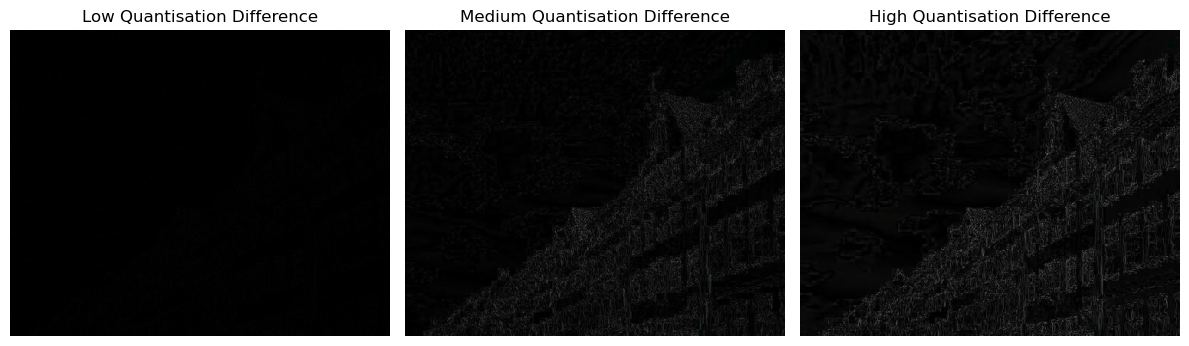

In [55]:
# 1. Load colour image
img = cv2.imread(
    r"C:\Users\hpw\Downloads\IPP_ASSIGNMENT_3\city.jpeg"
)
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

# 2. Make image dimensions divisible by 8
h = (img.shape[0] // 8) * 8
w = (img.shape[1] // 8) * 8
img = img[:h, :w]

# 3. Convert to YCrCb
ycc = cv2.cvtColor(img, cv2.COLOR_RGB2YCrCb)
Y, Cr, Cb = cv2.split(ycc)

# 4. JPEG quantisation matrix
Q = np.array([
    [16, 11, 10, 16, 24, 40, 51, 61],
    [12, 12, 14, 19, 26, 58, 60, 55],
    [14, 13, 16, 24, 40, 57, 69, 56],
    [14, 17, 22, 29, 51, 87, 80, 62],
    [18, 22, 37, 56, 68, 109, 103, 77],
    [24, 35, 55, 64, 81, 104, 113, 92],
    [49, 64, 78, 87, 103, 121, 120, 101],
    [72, 92, 95, 98, 112, 100, 103, 99]
], dtype=np.float32)

# 5. Function for JPEG-style compression
def compress_image(Y, factor):
    Y = np.float32(Y)
    h, w = Y.shape
    compressed_Y = np.zeros_like(Y)

    for i in range(0, h, 8):
        for j in range(0, w, 8):
            block = Y[i:i+8, j:j+8]

            dct_block = cv2.dct(block)

            quantized = np.round(dct_block / (Q * factor))
            dequant = quantized * (Q * factor)

            idct_block = cv2.idct(dequant)
            compressed_Y[i:i+8, j:j+8] = idct_block

    compressed_ycc = cv2.merge([np.clip(compressed_Y, 0, 255).astype(np.uint8),Cr, Cb])
    compressed_rgb = cv2.cvtColor(compressed_ycc, cv2.COLOR_YCrCb2RGB)
    return compressed_rgb

# 6. Compress using three quantisation levels
low = compress_image(Y, 0.5)
medium = compress_image(Y, 5)
high = compress_image(Y, 10)

# 7. Calculate PSNR and SSIM
images = [low, medium, high]
names = ["Low Quantisation", "Medium Quantisation","High Quantisation"]

for name, compressed in zip(names, images):
    psnr = cv2.PSNR(img, compressed)
    ssim_value = ssim(img, compressed, channel_axis=2, data_range=255)
    print(name)
    print("PSNR:", round(psnr, 2))
    print("SSIM:", round(ssim_value, 4))
    print()

# 8. Display results
plt.figure(figsize=(12, 8))

plt.subplot(2, 2, 1)
plt.imshow(img)
plt.title("Original Image")
plt.axis("off")

plt.subplot(2, 2, 2)
plt.imshow(low)
plt.title("Low Quantisation")
plt.axis("off")

plt.subplot(2, 2, 3)
plt.imshow(medium)
plt.title("Medium Quantisation")
plt.axis("off")

plt.subplot(2, 2, 4)
plt.imshow(high)
plt.title("High Quantisation")
plt.axis("off")

plt.tight_layout()
plt.show()

plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(cv2.absdiff(img, low))
plt.title("Low Quantisation Difference")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(cv2.absdiff(img, medium))
plt.title("Medium Quantisation Difference")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(cv2.absdiff(img, high))
plt.title("High Quantisation Difference")
plt.axis("off")

plt.tight_layout()
plt.show()

### Low Quantisation (0.5): 
The difference image is almost black, meaning very little information changed from the original.
### Medium Quantisation (5): 
More differences are visible, especially around building edges and textures.
### High Quantisation (10): 
The differences are stronger, showing that more image information was lost during compression.

### Observation

At low quantisation, the compressed image remains very similar to the original. At medium and high quantisation, more differences appear around building edges, windows, and cloud textures. As the quantisation factor increases, more DCT information is removed, resulting in greater image distortion. PSNR and SSIM generally decrease as quantisation becomes stronger.

### Conclusion

Low quantisation preserves image quality, whereas high quantisation produces greater information loss. Difference images help identify the areas affected by compression.

## Problem 5: Texture-Based Segmentation using GLCM Features

## Load a natural or synthetic image containing multiple textures. Extract GLCM features such as contrast, energy, and homogeneity for each pixel neighbourhood. Segment the image into three clusters using these features. Observe how feature selection affects segmentation quality.

Mean Contrast: 5.315
Mean Energy: 0.34760252
Mean Homogeneity: 0.53837067


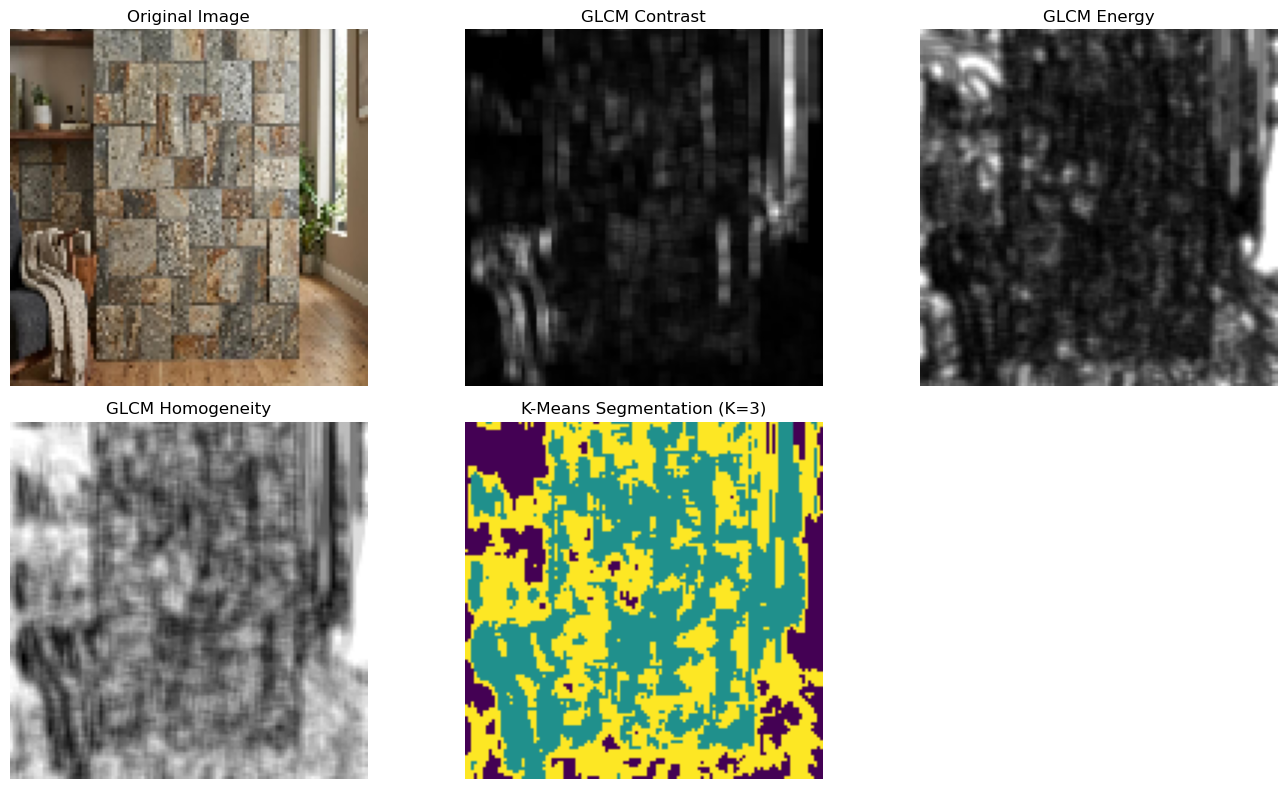

In [56]:
# 1. Load and convert to grayscale
img = cv2.imread(r"C:\Users\hpw\Downloads\IPP_ASSIGNMENT_3\texture.jpg")

if img is None:
    print("Image not found. Check the file path.")

else:
    img = cv2.resize(img, (120, 120))
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    # Reduce gray levels
    gray = (gray // 16).astype(np.uint8)

    # 2. Create arrays for GLCM features
    contrast = np.zeros(gray.shape, dtype=np.float32)
    energy = np.zeros(gray.shape, dtype=np.float32)
    homogeneity = np.zeros(gray.shape, dtype=np.float32)

    # 3. Extract GLCM features from each neighbourhood
    padded = cv2.copyMakeBorder(gray, 2, 2, 2, 2, cv2.BORDER_REFLECT)

    for i in range(gray.shape[0]):
        for j in range(gray.shape[1]):
            block = padded[i:i+5, j:j+5]
            glcm = graycomatrix(
                block,
                distances=[1],
                angles=[0],
                levels=16,
                symmetric=True,
                normed=True
            )

            contrast[i, j] = graycoprops(glcm, 'contrast')[0, 0]
            energy[i, j] = graycoprops(glcm, 'energy')[0, 0]
            homogeneity[i, j] = graycoprops(glcm, 'homogeneity')[0, 0]

    # 4. Display texture feature values
    print("Mean Contrast:", np.mean(contrast))
    print("Mean Energy:", np.mean(energy))
    print("Mean Homogeneity:", np.mean(homogeneity))

    # 5. Prepare GLCM features for K-means
    features = np.stack([contrast, energy, homogeneity], axis=2)

    h, w = gray.shape
    pixels = features.reshape((-1, 3)).astype(np.float32)

    # Scale features to a similar range
    for i in range(3):
        pixels[:, i] = cv2.normalize(pixels[:, i], None, 0, 1, cv2.NORM_MINMAX).flatten()

    # 6. K-means segmentation
    criteria = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER,20,1.0)
    k = 3
    _, labels, centers = cv2.kmeans(pixels,k,None,criteria,attempts=10,flags=cv2.KMEANS_PP_CENTERS)
    segmented = labels.reshape((h, w))

    # 7. Display results
    plt.figure(figsize=(14, 8))

    plt.subplot(2, 3, 1)
    plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    plt.title("Original Image")
    plt.axis("off")

    plt.subplot(2, 3, 2)
    plt.imshow(contrast, cmap="gray")
    plt.title("GLCM Contrast")
    plt.axis("off")

    plt.subplot(2, 3, 3)
    plt.imshow(energy, cmap="gray")
    plt.title("GLCM Energy")
    plt.axis("off")

    plt.subplot(2, 3, 4)
    plt.imshow(homogeneity, cmap="gray")
    plt.title("GLCM Homogeneity")
    plt.axis("off")

    plt.subplot(2, 3, 5)
    plt.imshow(segmented, cmap="viridis", vmin=0, vmax=2)
    plt.title("K-Means Segmentation (K=3)")
    plt.axis("off")

    plt.tight_layout()
    plt.show()


### Observation

GLCM contrast, energy, and homogeneity describe different properties of local image textures. K-means groups similar texture patterns into three clusters. The segmentation contains some mixed regions because different areas can have similar texture features.

### Conclusion

Combining multiple GLCM features helps identify regions with different textures. Segmentation quality depends on the image and the selected features.

## Problem 6: Multi-Feature Segmentation for Disease Detection

## Load a plant or skin lesion image. Construct a feature vector combining intensity, gradient magnitude using Sobel, and local texture variance. Segment the image using K-means or Mean Shift. Evaluate which feature contributes most to separating diseased and healthy regions and identify any misclassifications.

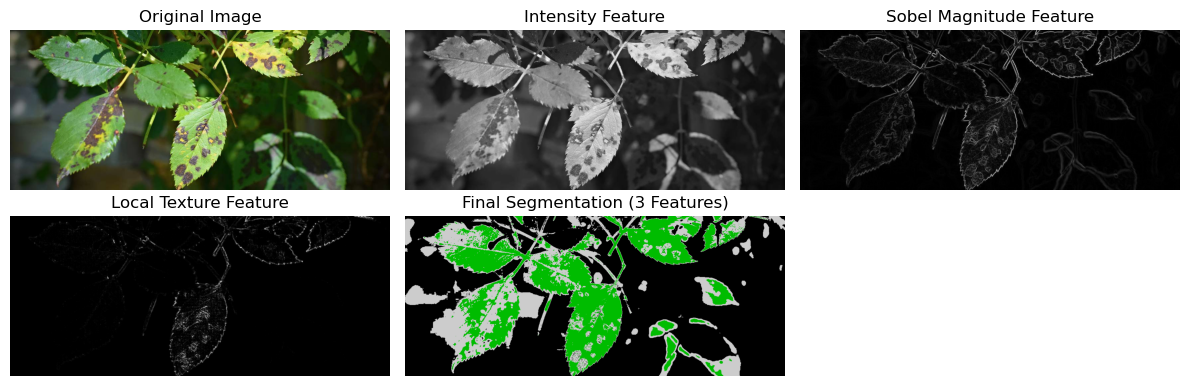

In [49]:
# 1. Load image
img = cv2.imread(r"C:\Users\hpw\Downloads\IPP_ASSIGNMENT_3\leaf.jpg")

if img is None:
    print("Image not found. Please check the file path.")

else:
    rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    # 2. Sobel magnitude
    sobel_x = cv2.Sobel(gray, cv2.CV_64F, 1, 0, ksize=3)
    sobel_y = cv2.Sobel(gray, cv2.CV_64F, 0, 1, ksize=3)
    sobel_mag = np.sqrt(sobel_x**2 + sobel_y**2)
    sobel_mag = cv2.normalize(sobel_mag, None, 0, 255, cv2.NORM_MINMAX)

    # 3. Local texture feature
    kernel = np.ones((3, 3), np.float32) / 9.0
    blur = cv2.filter2D(gray, -1, kernel)
    local_var = (gray.astype(np.float32) - blur.astype(np.float32))**2
    local_var = cv2.normalize(local_var, None, 0, 255, cv2.NORM_MINMAX)

    # 4. Prepare feature vector
    feature_vector = np.stack([gray,sobel_mag.astype(np.uint8),local_var.astype(np.uint8)], axis=2)

    # Flatten to N x 3 for K-means
    h, w = gray.shape
    fv_flat = feature_vector.reshape((-1, 3)).astype(np.float32)

    # 5. K-means clustering
    criteria = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER,30,1.0)
    k = 3
    _, labels, centers = cv2.kmeans(fv_flat,k,None,criteria,attempts=10,flags=cv2.KMEANS_PP_CENTERS)
    segmented = labels.reshape((h, w))

    # 6. Display results
    plt.figure(figsize=(12, 4))

    plt.subplot(2, 3, 1)
    plt.imshow(rgb)
    plt.title("Original Image")
    plt.axis("off")

    plt.subplot(2, 3, 2)
    plt.imshow(gray, cmap="gray")
    plt.title("Intensity Feature")
    plt.axis("off")

    plt.subplot(2, 3, 3)
    plt.imshow(sobel_mag, cmap="gray")
    plt.title("Sobel Magnitude Feature")
    plt.axis("off")

    plt.subplot(2, 3, 4)
    plt.imshow(local_var, cmap="gray", vmin=0, vmax=50)
    plt.title("Local Texture Feature")
    plt.axis("off")

    plt.subplot(2, 3, 5)
    plt.imshow(segmented, cmap="nipy_spectral")
    plt.title("Final Segmentation (3 Features)")
    plt.axis("off")

    plt.tight_layout()
    plt.show()


### Observation

Intensity separates regions based on brightness, Sobel gradient magnitude highlights edges, and local texture variance identifies changes in texture. K-means groups pixels using all three features. Some healthy and diseased regions may be grouped together when their features are similar.

### Conclusion

Combining intensity, gradient magnitude, and local texture can improve segmentation compared with using intensity alone. However, the clusters do not automatically identify disease; visual inspection is needed to interpret the segmented regions.